In [1]:
import re
import nltk
import numpy as np
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Cleaned text:
 
artificial intelligence is one of my favorite topics
it helps computers learn from data and solve complex problems
ai is used in healthcare education and transportation
i enjoy learning how machine learning models make predictions
in the future artificial intelligence may make our lives easier


Word tokens: ['Artificial', 'intelligence', 'is', 'one', 'of', 'my', 'favorite', 'topics', '.', 'It', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', '.', 'AI', 'is', 'used', 'in', 'healthcare', ',', 'education', ',', 'and', 'transportation', '.', 'I', 'enjoy', 'learning', 'how', 'machine', 'learning', 'models', 'make', 'predictions', '.', 'In', 'the', 'future', ',', 'artificial', 'intelligence', 'may', 'make', 'our', 'lives', 'easier', '.']

Sentence tokens: ['\nArtificial intelligence is one of my favorite topics.', 'It helps computers learn from data and solve complex problems.', 'AI is used in healthcare, education, and transportation.',

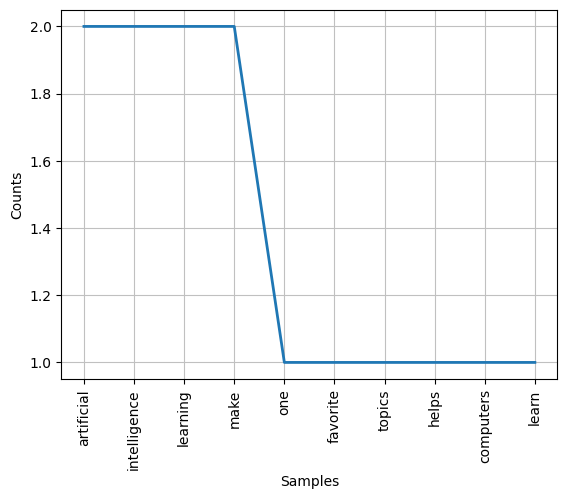

In [2]:
text = """
Artificial intelligence is one of my favorite topics.
It helps computers learn from data and solve complex problems.
AI is used in healthcare, education, and transportation.
I enjoy learning how machine learning models make predictions.
In the future, artificial intelligence may make our lives easier.
"""

# 1. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned text:\n", clean_text)

# 2. Tokenize into words and sentences
words = word_tokenize(text)
sentences = sent_tokenize(text)

print("\nWord tokens:", words)
print("\nSentence tokens:", sentences)

# 3. Compare split() and word_tokenize()
print("\nUsing split():", text.split())
print("\nUsing word_tokenize():", word_tokenize(text))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in word_tokenize(clean_text)
    if word not in stop_words
]

print("\nWords after stopword removal:", filtered_words)

# 5. Word frequency distribution
freq_dist = nltk.FreqDist(filtered_words)

print("\nWord frequencies:")
print(freq_dist.most_common())

freq_dist.plot(10)
plt.show()

In [3]:
# 1. Extract alphabetic words using re.findall()
alphabetic_words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic words:", alphabetic_words)

# 2. Remove stopwords
filtered_words = [
    word for word in alphabetic_words
    if word not in stop_words
]

print("\nAfter stopword removal:", filtered_words)

# 3. Stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]

print("\nStemmed words:", stemmed_words)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]

print("\nLemmatized words:", lemmatized_words)

# 5. Comparison
print("\nOriginal words:", filtered_words)
print("Stemmed words:", stemmed_words)
print("Lemmatized words:", lemmatized_words)

Alphabetic words: ['artificial', 'intelligence', 'is', 'one', 'of', 'my', 'favorite', 'topics', 'it', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'i', 'enjoy', 'learning', 'how', 'machine', 'learning', 'models', 'make', 'predictions', 'in', 'the', 'future', 'artificial', 'intelligence', 'may', 'make', 'our', 'lives', 'easier']

After stopword removal: ['artificial', 'intelligence', 'one', 'favorite', 'topics', 'helps', 'computers', 'learn', 'data', 'solve', 'complex', 'problems', 'ai', 'used', 'healthcare', 'education', 'transportation', 'enjoy', 'learning', 'machine', 'learning', 'models', 'make', 'predictions', 'future', 'artificial', 'intelligence', 'may', 'make', 'lives', 'easier']

Stemmed words: ['artifici', 'intellig', 'one', 'favorit', 'topic', 'help', 'comput', 'learn', 'data', 'solv', 'complex', 'problem', 'ai', 'use', 'healthcar', 'educ', 'transport', 'enjo

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps computers learn and solve problems.",
    "Electric vehicles reduce pollution and improve transportation.",
    "Machine learning helps doctors detect diseases early."
]

# 1. Bag of Words
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words feature names:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF matrix:")
print(np.round(tfidf_matrix.toarray(), 3))

# 3. Top 3 keywords for each text
feature_names = tfidf_vectorizer.get_feature_names_out()

for i, text_item in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]

    print(f"\nText {i+1}: {text_item}")
    print("Top 3 keywords:")

    for index in top_indices:
        print(feature_names[index], ":", round(scores[index], 3))

Bag of Words feature names:
['and' 'artificial' 'computers' 'detect' 'diseases' 'doctors' 'early'
 'electric' 'helps' 'improve' 'intelligence' 'learn' 'learning' 'machine'
 'pollution' 'problems' 'reduce' 'solve' 'transportation' 'vehicles']

Bag of Words matrix:
[[1 1 1 0 0 0 0 0 1 0 1 1 0 0 0 1 0 1 0 0]
 [1 0 0 0 0 0 0 1 0 1 0 0 0 0 1 0 1 0 1 1]
 [0 0 0 1 1 1 1 0 1 0 0 0 1 1 0 0 0 0 0 0]]

TF-IDF matrix:
[[0.284 0.374 0.374 0.    0.    0.    0.    0.    0.284 0.    0.374 0.374
  0.    0.    0.    0.374 0.    0.374 0.    0.   ]
 [0.297 0.    0.    0.    0.    0.    0.    0.39  0.    0.39  0.    0.
  0.    0.    0.39  0.    0.39  0.    0.39  0.39 ]
 [0.    0.    0.    0.39  0.39  0.39  0.39  0.    0.297 0.    0.    0.
  0.39  0.39  0.    0.    0.    0.    0.    0.   ]]

Text 1: Artificial intelligence helps computers learn and solve problems.
Top 3 keywords:
solve : 0.374
intelligence : 0.374
learn : 0.374

Text 2: Electric vehicles reduce pollution and improve transportation.
Top 3 ke

In [5]:
from sklearn.metrics.pairwise import cosine_similarity

text1 = """
Artificial intelligence enables machines to learn from data.
It can solve problems, recognize patterns, and make predictions.
AI is widely used in healthcare and education.
"""

text2 = """
Blockchain is a decentralized digital ledger.
It stores transactions securely across multiple computers.
Blockchain is widely used in finance and digital payments.
"""

# 1. Preprocess and tokenize
def preprocess(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    tokens = word_tokenize(text)
    return [word for word in tokens if word not in stop_words]

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Text 1 tokens:", tokens1)
print("Text 2 tokens:", tokens2)

# 2a. Jaccard similarity
set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))
print("\nJaccard Similarity:", round(jaccard, 3))

# 2b. Cosine similarity using TF-IDF
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform([text1, text2])

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]
print("Cosine Similarity:", round(cosine, 3))

Text 1 tokens: ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'solve', 'problems', 'recognize', 'patterns', 'make', 'predictions', 'ai', 'widely', 'used', 'healthcare', 'education']
Text 2 tokens: ['blockchain', 'decentralized', 'digital', 'ledger', 'stores', 'transactions', 'securely', 'across', 'multiple', 'computers', 'blockchain', 'widely', 'used', 'finance', 'digital', 'payments']

Jaccard Similarity: 0.069
Cosine Similarity: 0.18


In [6]:
!pip install textblob wordcloud


Review: This product is excellent and works perfectly.
Polarity: 1.0
Subjectivity: 1.0
Sentiment: Positive

Review: I love the quality and the service is amazing.
Polarity: 0.55
Subjectivity: 0.75
Sentiment: Positive

Review: The product is terrible and completely disappointing.
Polarity: -0.8
Subjectivity: 0.85
Sentiment: Negative

Review: Very poor quality and I am unhappy with the purchase.
Polarity: -0.56
Subjectivity: 0.84
Sentiment: Negative

Review: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive


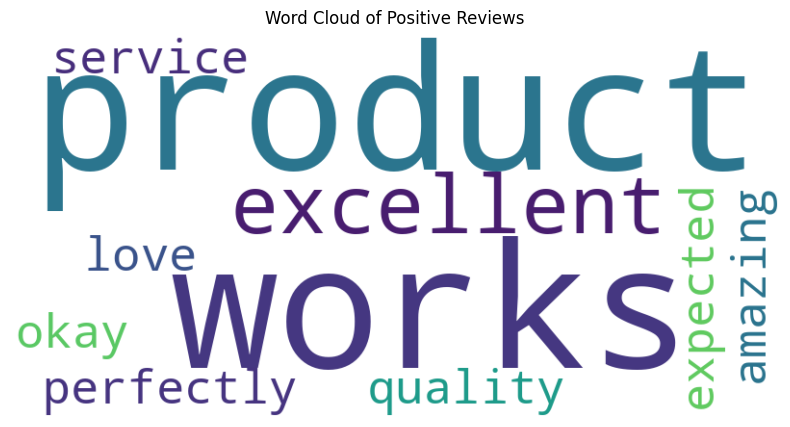

In [7]:
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "This product is excellent and works perfectly.",
    "I love the quality and the service is amazing.",
    "The product is terrible and completely disappointing.",
    "Very poor quality and I am unhappy with the purchase.",
    "The product is okay and works as expected."
]

positive_reviews = []

for review in reviews:
    analysis = TextBlob(review).sentiment
    polarity = analysis.polarity
    subjectivity = analysis.subjectivity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

    if sentiment == "Positive":
        positive_reviews.append(review)

# Word cloud for positive reviews
positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()

In [8]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training paragraph (~100 words)
training_text = """
Technology has changed the way people live and work.
Artificial intelligence helps computers learn from data.
Machine learning allows systems to recognize patterns.
Deep learning uses neural networks to solve complex tasks.
Computers can process information quickly and accurately.
Technology is used in education, healthcare, and business.
Students use computers to learn new skills and explore ideas.
Doctors use intelligent systems to support medical decisions.
Technology also helps people communicate across the world.
The future of technology depends on creativity and innovation.
Learning new technologies can help people solve real problems.
Artificial intelligence and machine learning continue to improve.
"""

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

sequences = tokenizer.texts_to_sequences([training_text])[0]

# 3. Create input sequences
input_sequences = []

for i in range(1, len(sequences)):
    input_sequences.append(sequences[:i+1])

max_sequence_length = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_length,
    padding='pre'
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

vocab_size = len(tokenizer.word_index) + 1

# 4. Build LSTM model
model = Sequential([
    Embedding(vocab_size, 32, input_length=max_sequence_length - 1),
    LSTM(64),
    Dense(vocab_size, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

# 5. Train the model
model.fit(X, y, epochs=100, verbose=1)

# 6. Generate text
def generate_text(seed_word, next_words=20):
    result = seed_word

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_length - 1,
            padding='pre'
        )

        predicted_probs = model.predict(token_list, verbose=0)[0]
        predicted_index = np.argmax(predicted_probs)

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_index:
                output_word = word
                break

        if output_word == "":
            break

        result += " " + output_word

    return result

print("Generated text:")
print(generate_text("technology", 20))
print(generate_text("artificial", 20))
print(generate_text("machine", 20))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 242ms/step - accuracy: 0.0306 - loss: 4.2344
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 337ms/step - accuracy: 0.0816 - loss: 4.2276
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - accuracy: 0.0714 - loss: 4.2228
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 169ms/step - accuracy: 0.0714 - loss: 4.2182
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 135ms/step - accuracy: 0.0612 - loss: 4.2134
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 298ms/step - accuracy: 0.0612 - loss: 4.2082
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 276ms/step - accuracy: 0.0612 - loss: 4.2025
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - accuracy: 0.0612 - loss: 4.1946
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 179ms/step - accuracy: 0.0612 - loss: 4.1830
Epoch 10/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 137ms/step - accuracy: 0.0612 - loss: 4.1500
Epoch 11/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - accuracy: 0.0612 - loss: 4.1032
Epoch 12/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 173ms/step - accuracy: